In [1]:
pip install ultralytics opencv-python-headless pillow pandas scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 61.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("icebearogo/german-traffic-sign-detection-gtsdb-dataset")

print("Path to dataset files:", path)

100%|██████████| 234M/234M [00:13<00:00, 17.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/icebearogo/german-traffic-sign-detection-gtsdb-dataset/versions/1


In [4]:
import os

print("Files and folders in downloaded dataset path:")
for root, dirs, files in os.walk(path):
    # Print depth of paths up to 3 levels
    level = root.replace(path, '').count(os.sep)
    if level < 3:
        indent = ' ' * 4 * (level)
        print(f"{indent}{os.path.basename(root)}/")
        subindent = ' ' * 4 * (level + 1)
        for f in files[:5]: # show up to 5 sample files per folder
            print(f"{subindent}{f}")

Files and folders in downloaded dataset path:
1/
    GTSDB_Train_and_Test/
        ReadME__(yes actually take a look).txt
        Test/
        Train/


In [5]:
import os
import glob
import shutil
import yaml

DATASET_ROOT = path
OUTPUT_DIR = "/content/gtsdb_yolo"

# Create standard YOLO directory tree
for split in ['train', 'val']:
    os.makedirs(os.path.join(OUTPUT_DIR, 'images', split), exist_ok=True)
    os.makedirs(os.path.join(OUTPUT_DIR, 'labels', split), exist_ok=True)

# Find all JPG/PNG images and TXT label files in the dataset
all_images = glob.glob(os.path.join(DATASET_ROOT, "**/*.jpg"), recursive=True) + \
             glob.glob(os.path.join(DATASET_ROOT, "**/*.png"), recursive=True)

print(f"Total images found: {len(all_images)}")

# Split images 80% train / 20% val
train_split = int(len(all_images) * 0.8)
train_imgs = all_images[:train_split]
val_imgs = all_images[train_split:]

def copy_files(img_list, split):
    for img_path in img_list:
        base_name = os.path.splitext(os.path.basename(img_path))[0]
        dir_name = os.path.dirname(img_path)

        # Copy image
        shutil.copy(img_path, os.path.join(OUTPUT_DIR, 'images', split, os.path.basename(img_path)))

        # Look for corresponding .txt label file
        txt_path = os.path.join(dir_name, f"{base_name}.txt")
        if os.path.exists(txt_path):
            shutil.copy(txt_path, os.path.join(OUTPUT_DIR, 'labels', split, f"{base_name}.txt"))

copy_files(train_imgs, 'train')
copy_files(val_imgs, 'val')

# Generate gtsdb.yaml
dataset_yaml = {
    'path': OUTPUT_DIR,
    'train': 'images/train',
    'val': 'images/val',
    'names': {
        0: 'speed_limit_20', 1: 'speed_limit_30', 2: 'speed_limit_50', 3: 'speed_limit_60',
        4: 'speed_limit_70', 5: 'speed_limit_80', 6: 'restriction_ends_80', 7: 'speed_limit_100',
        8: 'speed_limit_120', 9: 'no_overtaking', 10: 'no_overtaking_trucks',
        11: 'priority_at_next_intersection', 12: 'priority_road', 13: 'yield', 14: 'stop',
        15: 'no_vehicles', 16: 'vehicles_over_3.5t_prohibited', 17: 'no_entry',
        18: 'general_caution', 19: 'dangerous_curve_left', 20: 'dangerous_curve_right',
        21: 'double_curve', 22: 'bumpy_road', 23: 'slippery_road', 24: 'road_narrows_right',
        25: 'road_work', 26: 'traffic_signals', 27: 'pedestrians', 28: 'children_crossing',
        29: 'bicycles_crossing', 30: 'ice_snow', 31: 'wild_animals_crossing',
        32: 'end_of_all_restrictions', 33: 'turn_right_ahead', 34: 'turn_left_ahead',
        35: 'ahead_only', 36: 'go_straight_or_right', 37: 'go_straight_or_left',
        38: 'keep_right', 39: 'keep_left', 40: 'roundabout_mandatory',
        41: 'end_of_no_overtaking', 42: 'end_of_no_overtaking_trucks'
    }
}

with open('/content/gtsdb.yaml', 'w') as f:
    yaml.dump(dataset_yaml, f)

print("Dataset prepared successfully and /content/gtsdb.yaml created!")

Total images found: 900
Dataset prepared successfully and /content/gtsdb.yaml created!


In [10]:
import os
import glob
import shutil
import yaml

DATASET_ROOT = path
OUTPUT_DIR = "/content/gtsdb_yolo"

# Reset and recreate clean output directories
if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)

for split in ['train', 'val']:
    os.makedirs(os.path.join(OUTPUT_DIR, 'images', split), exist_ok=True)
    os.makedirs(os.path.join(OUTPUT_DIR, 'labels', split), exist_ok=True)

# 1. Find all label files and map base name -> full label path
all_txt_files = glob.glob(os.path.join(DATASET_ROOT, "**/*.txt"), recursive=True)
label_map = {}
for txt in all_txt_files:
    # Exclude non-label txt files if any exist
    if os.path.basename(txt).lower() in ["readme.txt", "classes.txt", "gt.txt"]:
        continue
    base_name = os.path.splitext(os.path.basename(txt))[0]
    label_map[base_name] = txt

print(f"Total annotation files found: {len(label_map)}")

# 2. Find all images
all_images = glob.glob(os.path.join(DATASET_ROOT, "**/*.jpg"), recursive=True) + \
             glob.glob(os.path.join(DATASET_ROOT, "**/*.png"), recursive=True) + \
             glob.glob(os.path.join(DATASET_ROOT, "**/*.ppm"), recursive=True)

print(f"Total images found: {len(all_images)}")

# Filter images so we prioritize images that have matching label files
matched_images = [img for img in all_images if os.path.splitext(os.path.basename(img))[0] in label_map]

if len(matched_images) == 0:
    print("⚠️ Warning: Could not match image filenames directly with text filenames.")
    print("Using all discovered images...")
    matched_images = all_images
else:
    print(f"Successfully matched {len(matched_images)} images with label files!")

# 3. Split 80% train / 20% val
train_split = int(len(matched_images) * 0.8)
train_imgs = matched_images[:train_split]
val_imgs = matched_images[train_split:]

def populate_yolo_split(img_list, split):
    copied_labels = 0
    for img_path in img_list:
        base_name = os.path.splitext(os.path.basename(img_path))[0]

        # Copy image
        dst_img = os.path.join(OUTPUT_DIR, 'images', split, os.path.basename(img_path))
        shutil.copy(img_path, dst_img)

        # Copy matching label file if found
        if base_name in label_map:
            dst_txt = os.path.join(OUTPUT_DIR, 'labels', split, f"{base_name}.txt")
            shutil.copy(label_map[base_name], dst_txt)
            copied_labels += 1

    print(f"[{split.upper()}] Copied {len(img_list)} images and {copied_labels} label text files.")

populate_yolo_split(train_imgs, 'train')
populate_yolo_split(val_imgs, 'val')

# 4. Write dataset configuration YAML
dataset_yaml = {
    'path': OUTPUT_DIR,
    'train': 'images/train',
    'val': 'images/val',
    'names': {
        0: 'speed_limit_20', 1: 'speed_limit_30', 2: 'speed_limit_50', 3: 'speed_limit_60',
        4: 'speed_limit_70', 5: 'speed_limit_80', 6: 'restriction_ends_80', 7: 'speed_limit_100',
        8: 'speed_limit_120', 9: 'no_overtaking', 10: 'no_overtaking_trucks',
        11: 'priority_at_next_intersection', 12: 'priority_road', 13: 'yield', 14: 'stop',
        15: 'no_vehicles', 16: 'vehicles_over_3.5t_prohibited', 17: 'no_entry',
        18: 'general_caution', 19: 'dangerous_curve_left', 20: 'dangerous_curve_right',
        21: 'double_curve', 22: 'bumpy_road', 23: 'slippery_road', 24: 'road_narrows_right',
        25: 'road_work', 26: 'traffic_signals', 27: 'pedestrians', 28: 'children_crossing',
        29: 'bicycles_crossing', 30: 'ice_snow', 31: 'wild_animals_crossing',
        32: 'end_of_all_restrictions', 33: 'turn_right_ahead', 34: 'turn_left_ahead',
        35: 'ahead_only', 36: 'go_straight_or_right', 37: 'go_straight_or_left',
        38: 'keep_right', 39: 'keep_left', 40: 'roundabout_mandatory',
        41: 'end_of_no_overtaking', 42: 'end_of_no_overtaking_trucks'
    }
}

with open('/content/gtsdb.yaml', 'w') as f:
    yaml.dump(dataset_yaml, f)

print("\nSetup complete! You can now re-run the training script.")

Total annotation files found: 742
Total images found: 900
Successfully matched 741 images with label files!
[TRAIN] Copied 592 images and 592 label text files.
[VAL] Copied 149 images and 149 label text files.

Setup complete! You can now re-run the training script.


In [11]:
from ultralytics import YOLO

model = YOLO('yolov8s.pt')

results = model.train(
    data='/content/gtsdb.yaml',
    epochs=100,
    imgsz=960,
    batch=8,
    fliplr=0.0,
    mosaic=1.0,
    name='yolov8s_gtsdb'
)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/gtsdb.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_gtsdb-3, nbs=64, nms=None, opset=None, optimize=False, optimiz

In [12]:
import os

# Check the run directory
weights_path = "/content/runs/detect/yolov8s_gtsdb-3/weights/best.pt"

# Also check alternative folder names if indexed differently
if not os.path.exists(weights_path):
    weights_path = "/content/runs/detect/yolov8s_gtsdb/weights/best.pt"

if os.path.exists(weights_path):
    print(f" SUCCESS! Your trained weights were found at:\n{weights_path}")
else:
    print(" Weights file not found in default runs folder.")

 SUCCESS! Your trained weights were found at:
/content/runs/detect/yolov8s_gtsdb-3/weights/best.pt


In [13]:
from google.colab import files

weights_path = "/content/runs/detect/yolov8s_gtsdb-3/weights/best.pt"
files.download(weights_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
from ultralytics import YOLO

model = YOLO('/content/runs/detect/yolov8s_gtsdb-3/weights/best.pt')

# Evaluate model performance on validation set
metrics = model.val(data='/content/gtsdb.yaml', imgsz=960)

print("\n--- FINAL EVALUATION METRICS ---")
print(f"Precision:    {metrics.box.mp:.4f}")
print(f"Recall:       {metrics.box.mr:.4f}")
print(f"mAP@0.5:      {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95: {metrics.box.map:.4f}")

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,142,225 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2518.7±497.3 MB/s, size: 315.9 KB)
val: Scanning /content/gtsdb_yolo/labels/val.cache... 149 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 149/149 36.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 1.4it/s 7.0s
                   all        149        149      0.281      0.324      0.308      0.283
        speed_limit_30          9          9      0.446      0.778      0.685       0.64
        speed_limit_50         16         16      0.308      0.312      0.263      0.241
        speed_limit_60          7          7      0.151      0.429       0.18      0.169
        speed_limit_70          5          5      0.099        0.2     0.0545     0.0504
        speed_limit_80          5          5

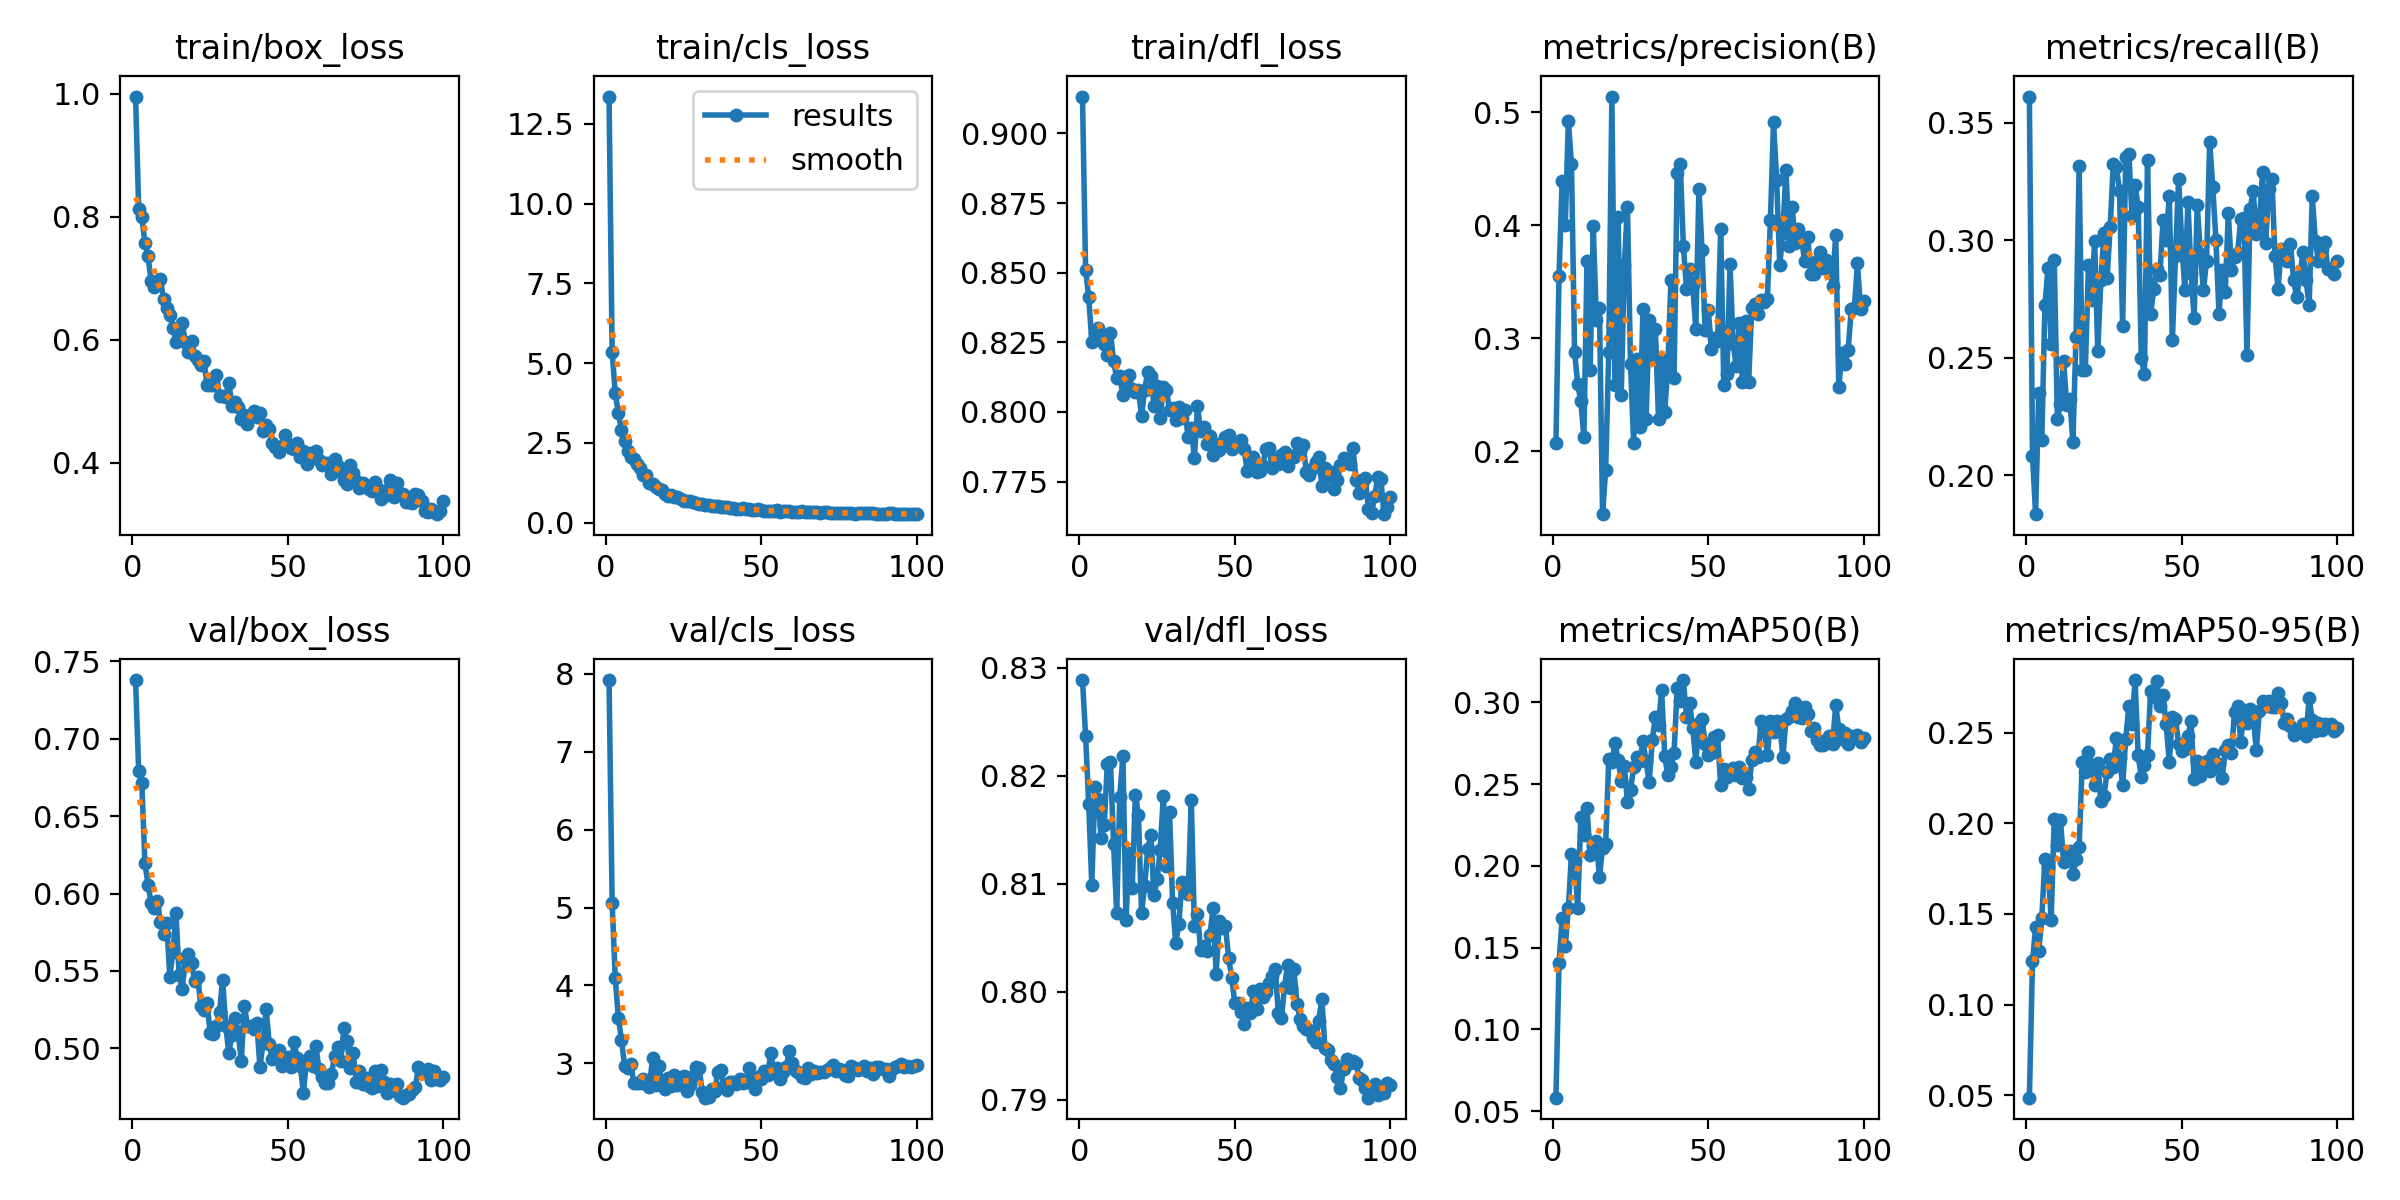

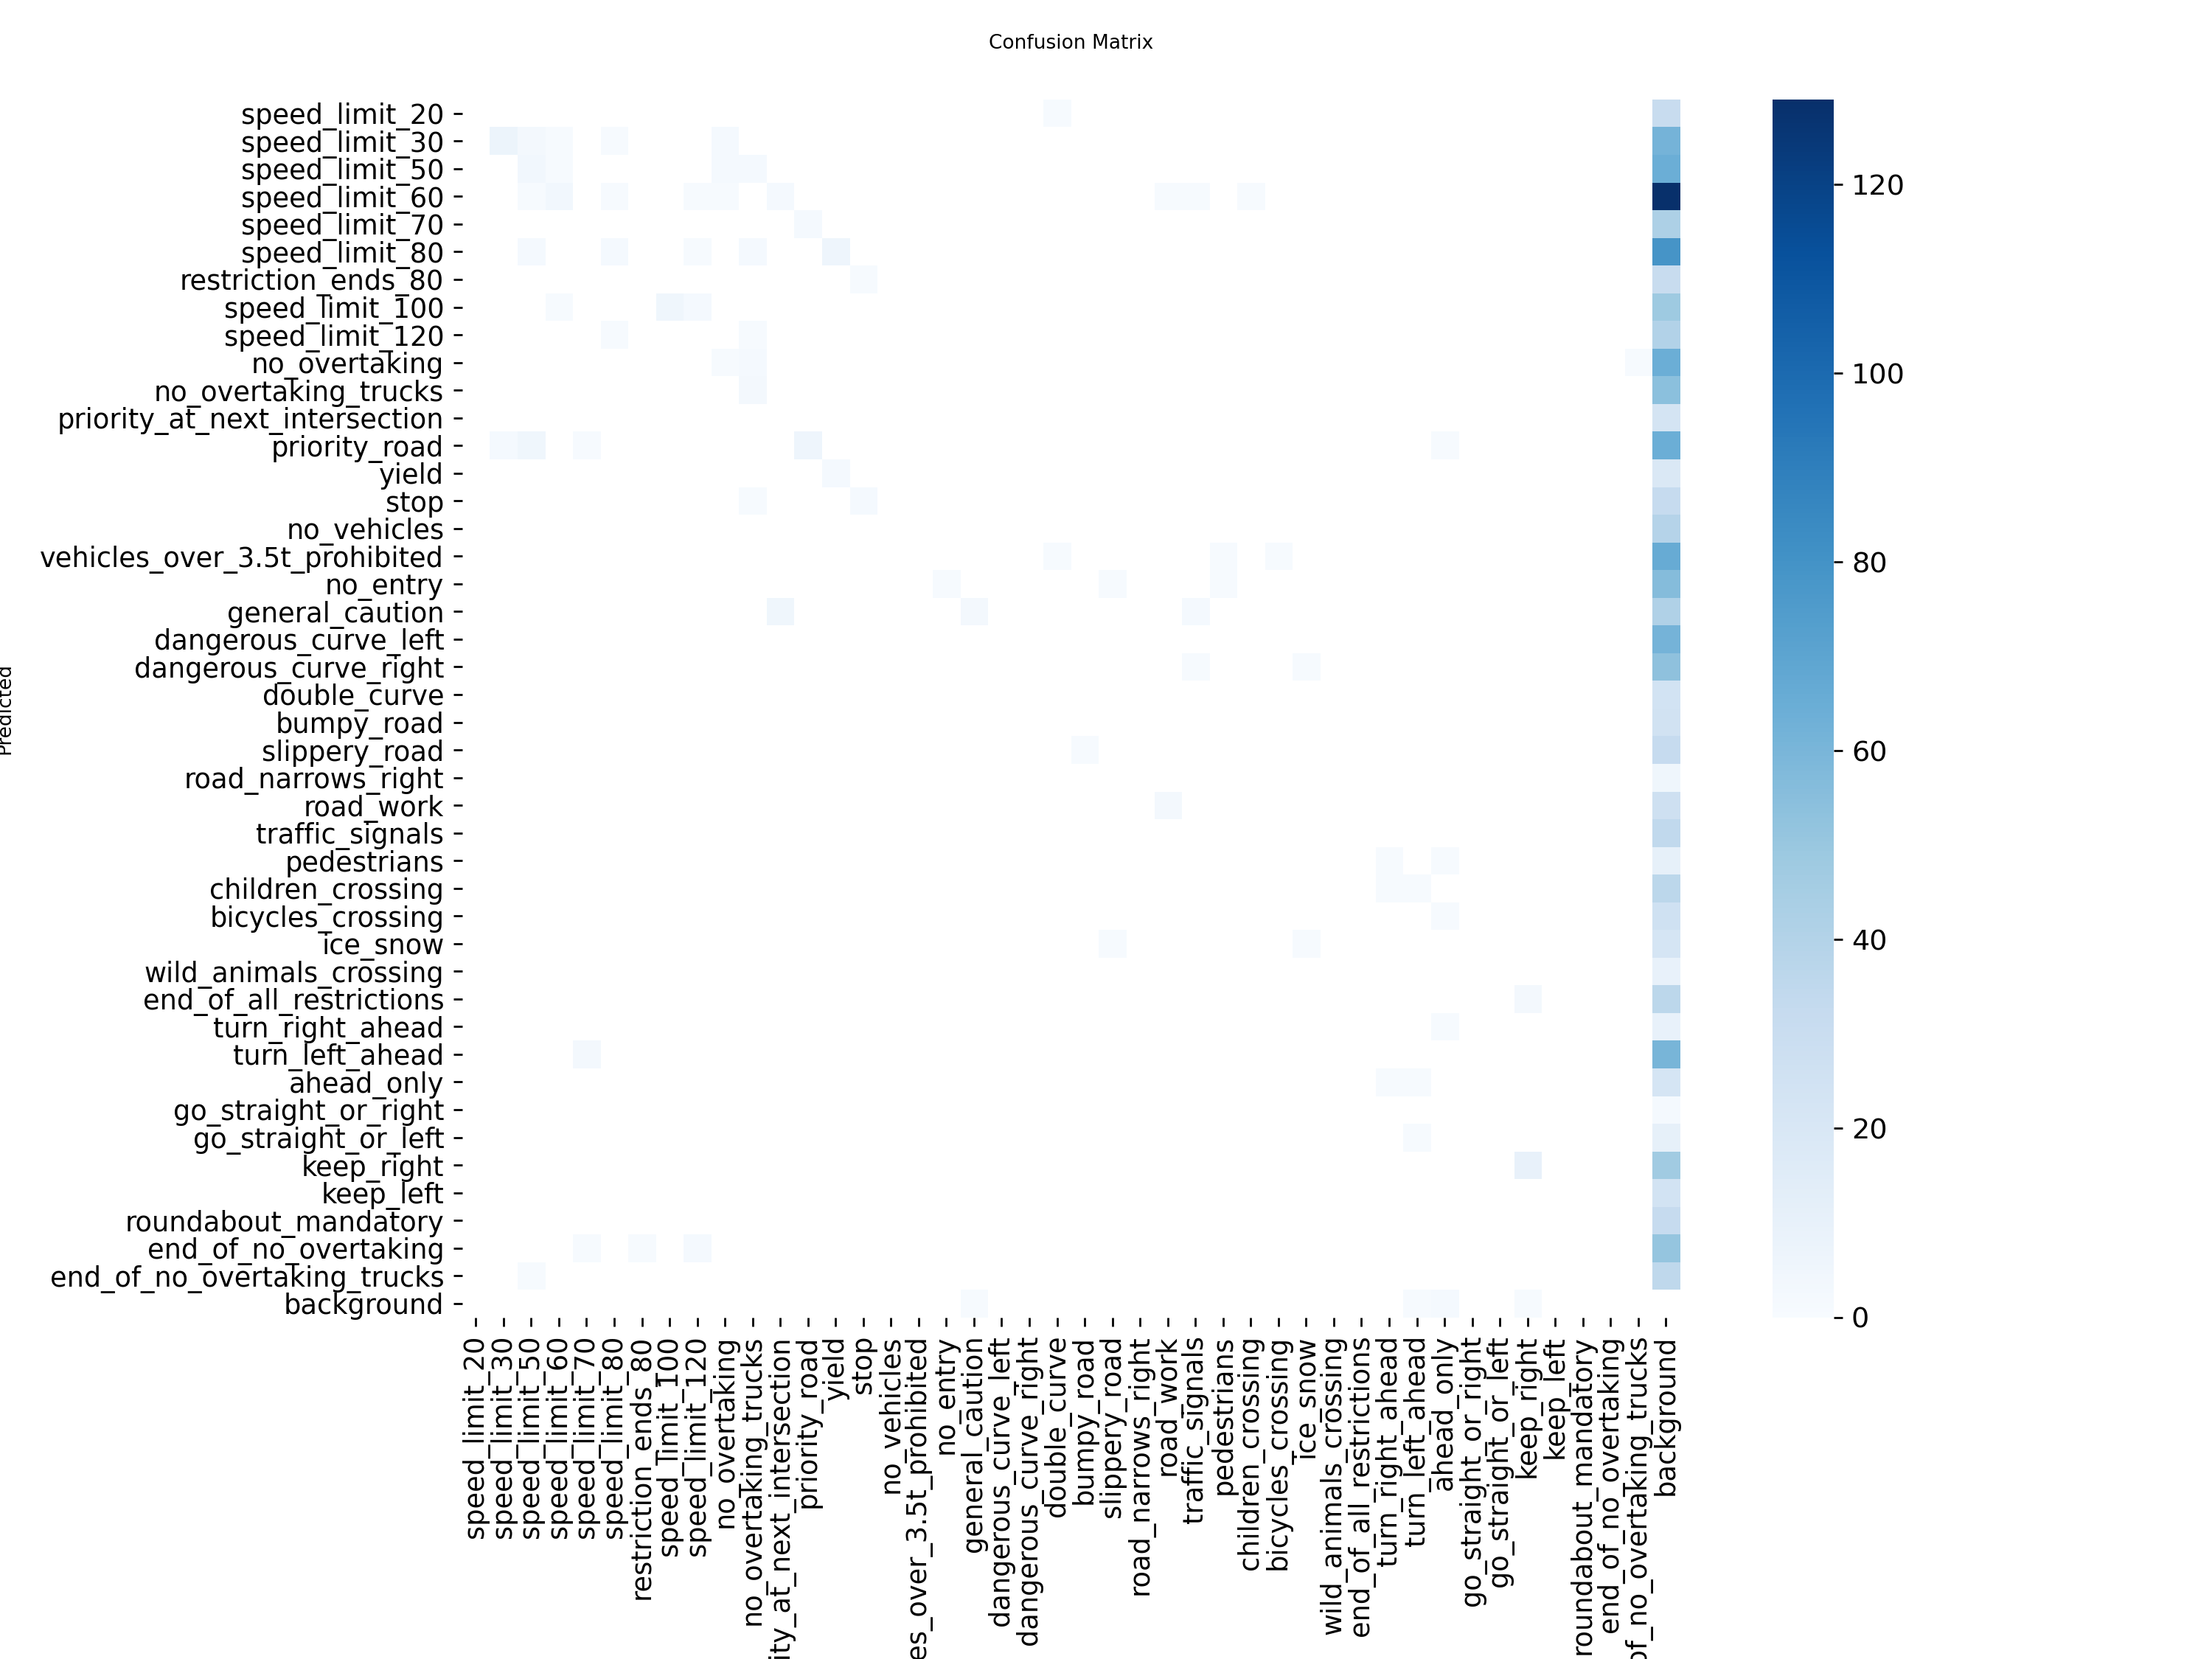

In [15]:
from IPython.display import Image, display

# View Training Loss & mAP progression curves
display(Image(filename='/content/runs/detect/yolov8s_gtsdb-3/results.png'))

# View Confusion Matrix
display(Image(filename='/content/runs/detect/yolov8s_gtsdb-3/confusion_matrix.png'))

In [16]:
# Export trained model to ONNX format
onnx_path = model.export(format='onnx', imgsz=960)

# Download ONNX file to your computer
files.download(onnx_path)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 72 layers, 11,142,225 parameters, 0 gradients, 64.2 GFLOPs

PyTorch: starting from '/content/runs/detect/yolov8s_gtsdb-3/weights/best.pt' with input shape (1, 3, 960, 960) BCHW and output shape(s) (1, 47, 18900) (21.5 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 237ms
Prepared 4 packages in 531ms
Installed 4 packages in 34ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.1
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
pip install ultralytics opencv-python

In [19]:
import cv2
import time
from ultralytics import YOLO

# Load your downloaded trained weights
model = YOLO('/content/runs/detect/yolov8s_gtsdb-3/weights/best.pt')

# Open laptop camera stream (0 is default webcam)
cap = cv2.VideoCapture(0)
conf_threshold = 0.40  # Filter out detections below 40% confidence

prev_time = time.time()

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        print("Failed to grab camera frame.")
        break

    # Run inference on live camera frame
    results = model.predict(frame, imgsz=960, conf=conf_threshold, verbose=False)[0]

    # Draw predictions onto frame
    annotated_frame = results.plot()

    # Calculate and overlay real-time FPS
    curr_time = time.time()
    fps = 1.0 / (curr_time - prev_time) if (curr_time - prev_time) > 0 else 0.0
    prev_time = curr_time

    cv2.putText(annotated_frame, f"FPS: {fps:.1f}", (20, 50),
                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)

    # Display window
    cv2.imshow("GTSDB Traffic Sign Recognition", annotated_frame)

    # Press 'q' to stop execution
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

<IPython.core.display.Javascript object>


image 1/1 /content/photo.jpg: 544x960 1 speed_limit_30, 35.1ms
Speed: 2.5ms preprocess, 35.1ms inference, 2.0ms postprocess per image at shape (1, 3, 544, 960)


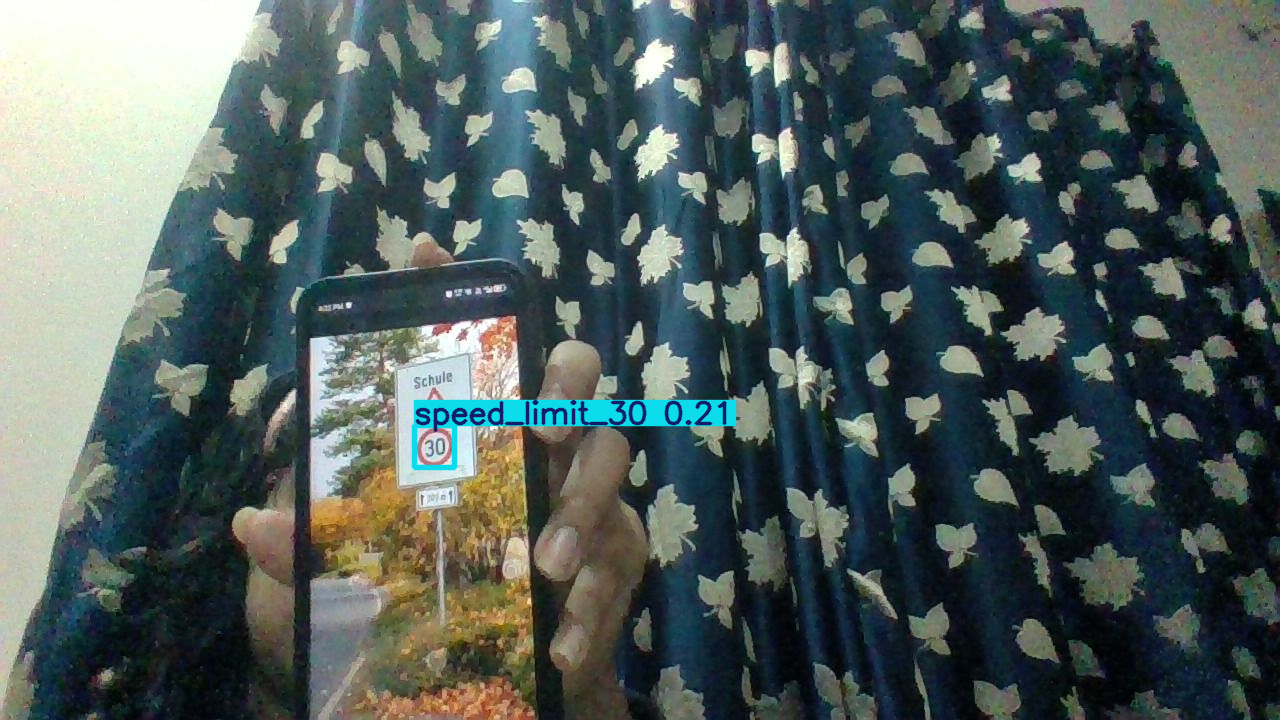

In [35]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow
import cv2
import numpy as np
import base64
from ultralytics import YOLO

# JavaScript function to capture webcam photo from browser
def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getTracks().forEach(track => track.stop());
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = base64.b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

# Take picture using webcam via browser
try:
  filename = take_photo()

  # Detect traffic signs on captured frame
  model = YOLO('/content/runs/detect/yolov8s_gtsdb-3/weights/best.pt')
  results = model.predict(filename, imgsz=960, conf=0.15)[0]

  # Display result in notebook
  cv2_imshow(results.plot())
except Exception as err:
  print(str(err))

<IPython.core.display.Javascript object>


image 1/1 /content/photo.jpg: 544x960 1 speed_limit_30, 35.1ms
Speed: 2.7ms preprocess, 35.1ms inference, 1.3ms postprocess per image at shape (1, 3, 544, 960)


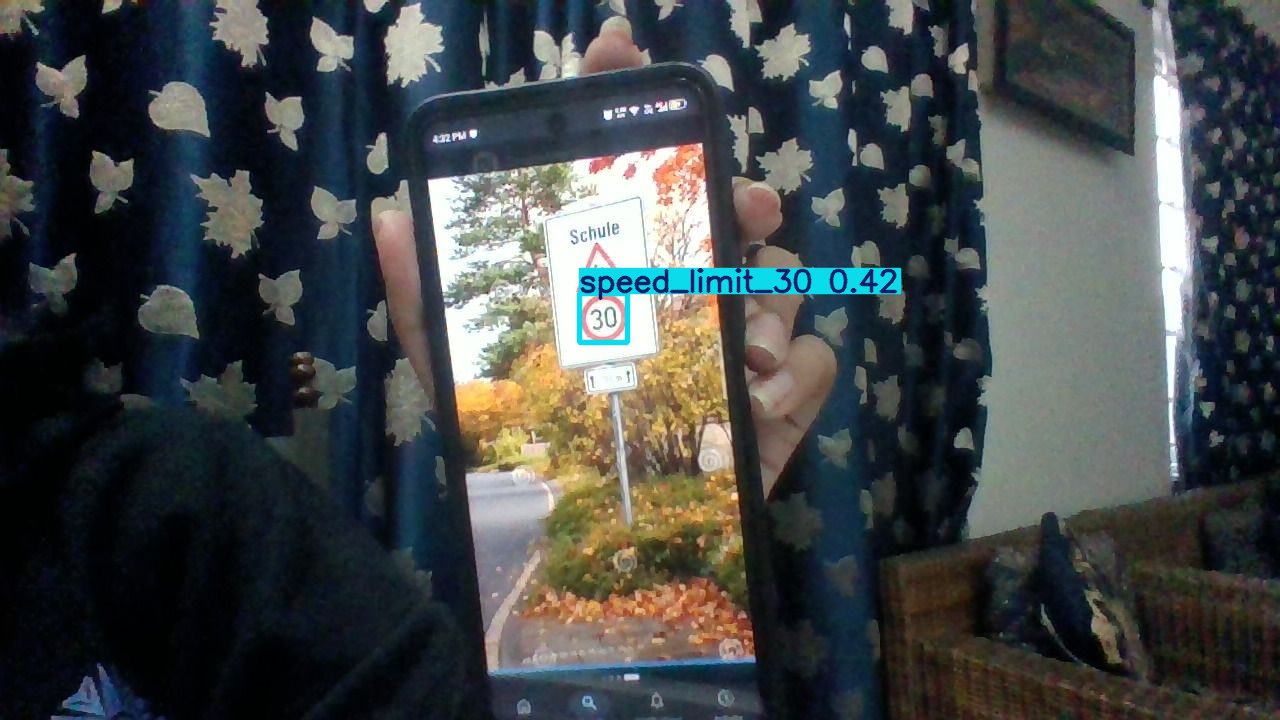

In [36]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow
import cv2
import numpy as np
import base64
from ultralytics import YOLO

# JavaScript function to capture webcam photo from browser
def take_photo(filename='photo.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getTracks().forEach(track => track.stop());
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = base64.b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

# Take picture using webcam via browser
try:
  filename = take_photo()

  # Detect traffic signs on captured frame
  model = YOLO('/content/runs/detect/yolov8s_gtsdb-3/weights/best.pt')
  results = model.predict(filename, imgsz=960, conf=0.15)[0]

  # Display result in notebook
  cv2_imshow(results.plot())
except Exception as err:
  print(str(err))

In [37]:
from ultralytics import YOLO

# Load best trained model
model = YOLO('/content/runs/detect/yolov8s_gtsdb-3/weights/best.pt')

# Run validation on the test split
metrics = model.val(data='/content/gtsdb.yaml', imgsz=960)

print(f"\n--- GTSDB BENCHMARK RESULTS ---")
print(f"Precision (P):       {metrics.box.mp:.4f}")
print(f"Recall (R):          {metrics.box.mr:.4f}")
print(f"mAP@0.5:             {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95:        {metrics.box.map:.4f}")

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,142,225 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1923.4±1048.7 MB/s, size: 309.7 KB)
val: Scanning /content/gtsdb_yolo/labels/val.cache... 149 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 149/149 28.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 1.6it/s 6.1s
                   all        149        149      0.281      0.324      0.308      0.283
        speed_limit_30          9          9      0.446      0.778      0.685       0.64
        speed_limit_50         16         16      0.308      0.312      0.263      0.241
        speed_limit_60          7          7      0.151      0.429       0.18      0.169
        speed_limit_70          5          5      0.099        0.2     0.0545     0.0504
        speed_limit_80          5          

Correction

In [38]:
import os
import glob

label_files = glob.glob("/content/gtsdb_yolo/labels/val/*.txt")

total_boxes = 0
multi_sign_images = 0

for lf in label_files:
    with open(lf, 'r') as f:
        lines = f.readlines()
        box_count = len(lines)
        total_boxes += box_count
        if box_count > 1:
            multi_sign_images += 1

print(f"Total Val Images: {len(label_files)}")
print(f"Total Bounding Boxes Found: {total_boxes}")
print(f"Images with >1 sign: {multi_sign_images}")

Total Val Images: 149
Total Bounding Boxes Found: 149
Images with >1 sign: 0


In [41]:
import os
import glob
import shutil
from sklearn.model_selection import train_test_split

DATASET_ROOT = path
OUTPUT_DIR = "/content/gtsdb_yolo_fixed"

if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)

# 1. Map existing TXT files
all_txt_files = glob.glob(os.path.join(DATASET_ROOT, "**/*.txt"), recursive=True)
label_map = {}
for txt in all_txt_files:
    fname = os.path.basename(txt).lower()
    if fname in ["readme.txt", "classes.txt", "gt.txt"]:
        continue
    base = os.path.splitext(os.path.basename(txt))[0]
    label_map[base] = txt

# 2. Collect images
all_images = glob.glob(os.path.join(DATASET_ROOT, "**/*.jpg"), recursive=True) + \
             glob.glob(os.path.join(DATASET_ROOT, "**/*.png"), recursive=True) + \
             glob.glob(os.path.join(DATASET_ROOT, "**/*.ppm"), recursive=True)

# Random shuffle split (80% train, 20% val)
train_imgs, val_imgs = train_test_split(all_images, test_size=0.2, random_state=42)
splits = {'train': train_imgs, 'val': val_imgs}

total_parsed_boxes = {'train': 0, 'val': 0}
multi_sign_counts = {'train': 0, 'val': 0}

for split, img_list in splits.items():
    img_out = os.path.join(OUTPUT_DIR, f"images/{split}")
    lbl_out = os.path.join(OUTPUT_DIR, f"labels/{split}")
    os.makedirs(img_out, exist_ok=True)
    os.makedirs(lbl_out, exist_ok=True)

    for img_path in img_list:
        base = os.path.splitext(os.path.basename(img_path))[0]

        # Copy image file
        shutil.copy(img_path, os.path.join(img_out, os.path.basename(img_path)))

        # Write ALL bounding boxes for this image
        dst_txt = os.path.join(lbl_out, f"{base}.txt")
        if base in label_map:
            valid_lines = []
            with open(label_map[base], 'r') as f_in:
                for line in f_in:
                    parts = line.strip().split()
                    if not parts:
                        continue
                    cls_id = int(parts[0])
                    if cls_id <= 42:
                        valid_lines.append(line.strip() + "\n")

            box_count = len(valid_lines)
            total_parsed_boxes[split] += box_count
            if box_count > 1:
                multi_sign_counts[split] += 1

            with open(dst_txt, 'w') as f_out:
                f_out.writelines(valid_lines)
        else:
            open(dst_txt, 'w').close()

print(f" SUCCESS!")
print(f"VAL Split: {len(splits['val'])} images, {total_parsed_boxes['val']} bounding boxes ({multi_sign_counts['val']} images contain >1 sign).")
print(f"TRAIN Split: {len(splits['train'])} images, {total_parsed_boxes['train']} bounding boxes ({multi_sign_counts['train']} images contain >1 sign).")

 SUCCESS!
VAL Split: 180 images, 170 bounding boxes (18 images contain >1 sign).
TRAIN Split: 720 images, 696 bounding boxes (80 images contain >1 sign).
